# 05 · Roads, rail and transit

The Overture road network at tract level: class mix and density, the highway classes the road component uses, what the class filter removes, how roads relate to urbanity, and where rail and transit exist.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import pathlib
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats

ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "data").exists())
DATA, OUT, ANALYSIS = ROOT / "data", ROOT / "eda_outputs", ROOT / "analysis_outputs"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25, "axes.titlesize": 11, "axes.labelsize": 9})
REG = ["maricopa-az", "northern-ca", "eastern-ok", "south-central-tx", "eastern-wa"]
NAME = {"maricopa-az": "Maricopa AZ", "northern-ca": "Northern CA", "eastern-ok": "Eastern OK", "south-central-tx": "S-C Texas", "eastern-wa": "Eastern WA"}
COL = dict(zip(REG, ["#e07b39", "#c0504d", "#6a9e4f", "#3b6fb6", "#8e6bbf"]))
df = pd.read_parquet(OUT / "base_table.parquet")

def box_by_region(ax, col, log=False, title="", ylabel=None, data=None):
    d = df if data is None else data
    vals = [d.loc[d.region == r, col].dropna() for r in REG]
    if log: vals = [np.log10(v[v > 0]) for v in vals]
    bp = ax.boxplot(vals, patch_artist=True, medianprops=dict(color="k"), flierprops=dict(marker=".", markersize=2, alpha=.3))
    for patch, r in zip(bp["boxes"], REG): patch.set_facecolor(COL[r]); patch.set_alpha(.75)
    ax.set_xticks(range(1, 6)); ax.set_xticklabels([f"{NAME[r]}\nn={len(v):,}" for r, v in zip(REG, vals)], fontsize=7.5)
    ax.set_title(title); ax.set_ylabel(ylabel or (("log10 " if log else "") + col))

def n_outliers(s):
    s = s.dropna(); q1, q3 = s.quantile([.25, .75]); k = 1.5 * (q3 - q1)
    return int(((s < q1 - k) | (s > q3 + k)).sum())

def heat(ax, M, fmt="{:.2f}", cmap="RdBu_r", vmin=-1, vmax=1, fs=7, rot=60):
    im = ax.imshow(M.values, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto"); ax.grid(False)
    ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(M.columns, rotation=rot, ha="right", fontsize=8)
    ax.set_yticks(range(M.shape[0])); ax.set_yticklabels(M.index, fontsize=8)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M.values[i, j]; ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=fs, color="k" if abs(v - (vmin + vmax) / 2) < (vmax - vmin) * .35 else "w")
    return im

## 1. Road network: how much, and which classes?

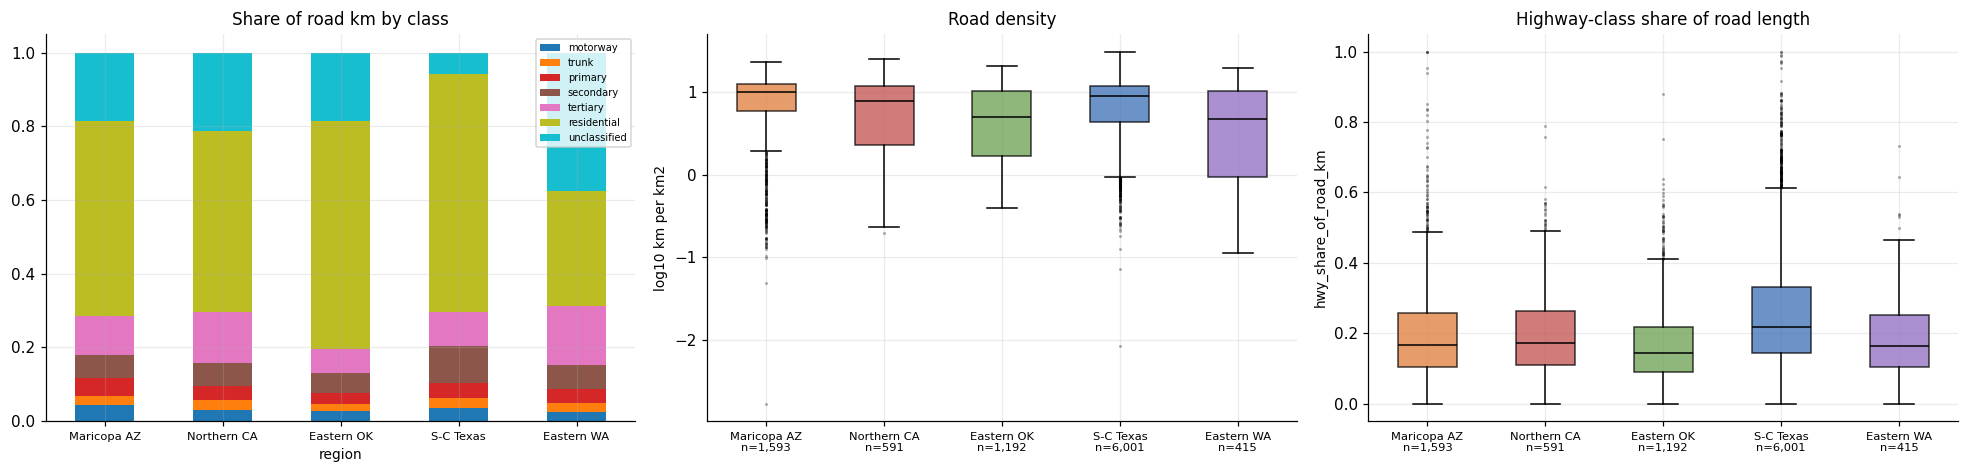

region
maricopa-az         124.0
northern-ca          77.0
eastern-ok          213.0
south-central-tx    576.0
eastern-wa           79.0

                  motorway  trunk  primary  secondary  tertiary  residential  unclassified
region                                                                                    
maricopa-az            4.5    2.4      4.7        6.3      10.6         52.8          18.7
northern-ca            3.1    2.6      3.9        6.1      14.0         48.9          21.3
eastern-ok             2.8    2.0      2.9        5.4       6.6         61.6          18.7
south-central-tx       3.5    2.8      4.1       10.0       9.0         64.8           5.7
eastern-wa             2.5    2.4      3.8        6.5      16.0         31.3          37.5

median density km/km2: {'maricopa-az': 10.0, 'northern-ca': 7.9, 'eastern-ok': 5.1, 'south-central-tx': 9.0, 'eastern-wa': 4.7}


In [2]:
cls = ["motorway", "trunk", "primary", "secondary", "tertiary", "residential", "unclassified"]
rk = df.groupby("region")[[f"road_km_{c}" for c in cls]].sum().reindex(REG); rk.columns = cls
fig, ax = plt.subplots(1, 3, figsize=(18, 4.4)); rk.div(rk.sum(axis=1), axis=0).plot.bar(stacked=True, ax=ax[0], rot=0, colormap="tab10"); ax[0].set_xticklabels([NAME[r] for r in REG], fontsize=7.5); ax[0].set_title("Share of road km by class"); ax[0].legend(fontsize=6.5)
box_by_region(ax[1], "road_km_per_km2", log=True, title="Road density", ylabel="log10 km per km2"); box_by_region(ax[2], "hwy_share_of_road_km", title="Highway-class share of road length")
plt.tight_layout(); plt.show(); print((rk.sum(axis=1) / 1e3).round(0).rename("road km (thousands)").to_string()); print(); print((rk.div(rk.sum(axis=1), axis=0) * 100).round(1).to_string()); print("\nmedian density km/km2:", df.groupby("region").road_km_per_km2.median().reindex(REG).round(1).to_dict())

**Takeaway:** residential streets dominate everywhere (49-65% of road km) except Eastern WA, where 'unclassified' is the largest class (38%). The four highway classes together are only 13-20% of road length. Texas has by far the most road (576 thousand km, vs 77-213 thousand elsewhere). Median road density runs from 4.7 km/km2 in Eastern WA to 10.0 in Maricopa.

## 2. The highway classes the target uses
The road component compares named highways (motorway, trunk, primary, secondary). How many tracts have any, and how much?

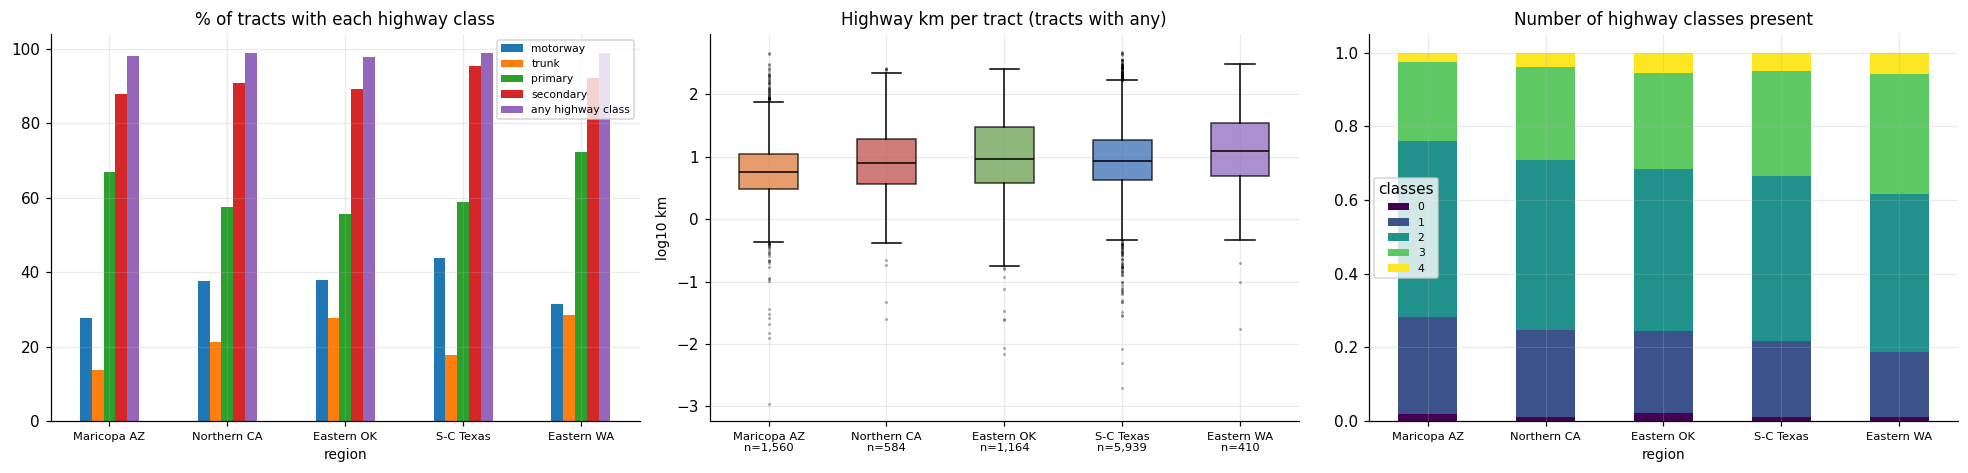

                  motorway  trunk  primary  secondary  any highway class
region                                                                  
maricopa-az           28.0   14.0     67.0       88.0               98.0
northern-ca           38.0   21.0     57.0       91.0               99.0
eastern-ok            38.0   28.0     56.0       89.0               98.0
south-central-tx      44.0   18.0     59.0       95.0               99.0
eastern-wa            31.0   28.0     72.0       92.0               99.0

tracts with no highway-class road: 137 | with all four: 444


In [3]:
hw = ["road_km_motorway", "road_km_trunk", "road_km_primary", "road_km_secondary"]
pres = pd.DataFrame({c.replace("road_km_", ""): df.groupby("region")[c].apply(lambda s: (s > 0).mean()) for c in hw + ["road_km_hwy"]}).reindex(REG).rename(columns={"hwy": "any highway class"})
fig, ax = plt.subplots(1, 3, figsize=(18, 4.4)); (pres * 100).plot.bar(ax=ax[0], rot=0); ax[0].set_xticklabels([NAME[r] for r in REG], fontsize=7.5); ax[0].set_title("% of tracts with each highway class"); ax[0].legend(fontsize=7)
box_by_region(ax[1], "road_km_hwy", log=True, title="Highway km per tract (tracts with any)", ylabel="log10 km")
n_cls = (df[hw] > 0).sum(axis=1); pd.crosstab(df.region, n_cls, normalize="index").reindex(REG).plot.bar(stacked=True, ax=ax[2], rot=0, colormap="viridis"); ax[2].set_xticklabels([NAME[r] for r in REG], fontsize=7.5); ax[2].set_title("Number of highway classes present"); ax[2].legend(title="classes", fontsize=7)
plt.tight_layout(); plt.show(); print((pres * 100).round(0).to_string()); print("\ntracts with no highway-class road:", int((df.road_km_hwy == 0).sum()), "| with all four:", int((n_cls == 4).sum()))

**Takeaway:** almost every tract (98-99%) has some highway-class road, but the individual classes are patchy: secondary roads are in 88-95% of tracts, primary in 56-72%, motorway in 28-44% and trunk in only 14-28%. Just 444 tracts (4.5%) have all four classes. 137 tracts have none. The road component is only defined where the reference highway network exists, and it is built on exactly these classes, so most of its variation will come from which classes are present in each tract.

## 3. What does the class filter remove?
The unfiltered road layer adds service roads, tracks and footpaths. They are not scored, but show how much of the network the filter ignores.

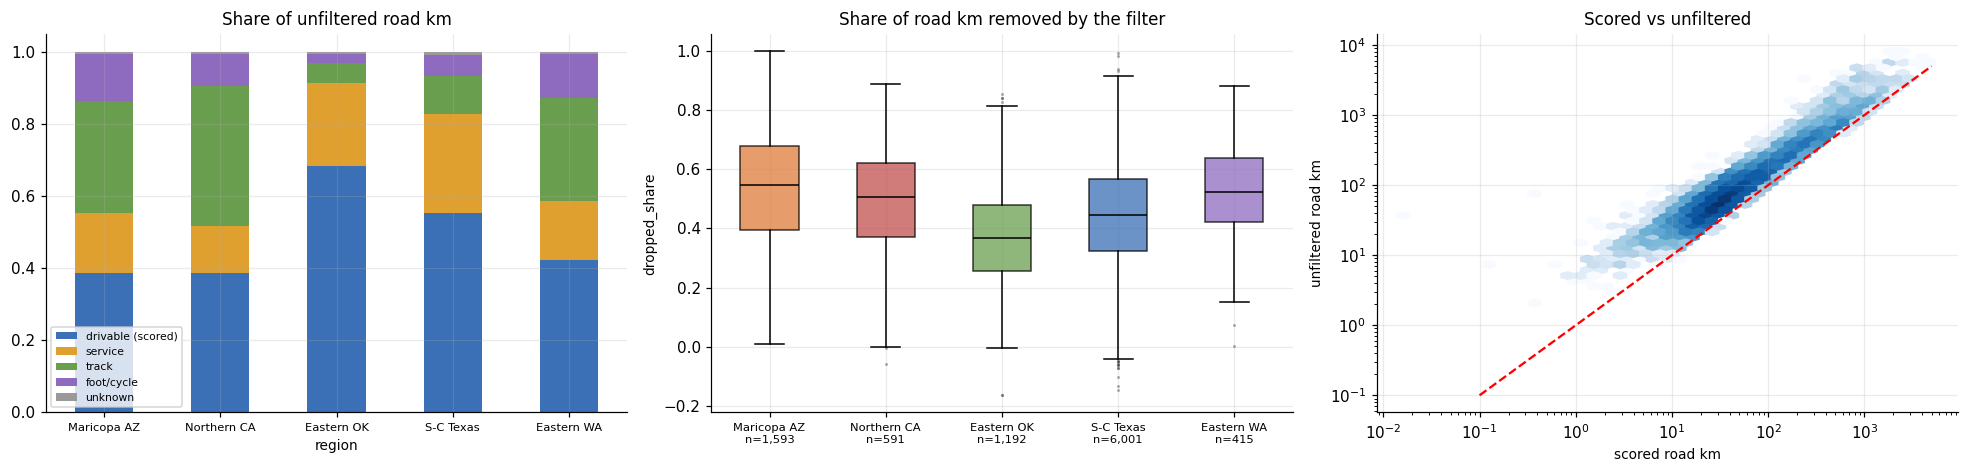

                  drivable (scored)  service  track  foot/cycle  unknown
region                                                                  
maricopa-az                    38.6     16.6   31.2        12.9      0.6
northern-ca                    38.6     13.2   38.7         9.1      0.4
eastern-ok                     68.5     22.9    5.6         2.6      0.5
south-central-tx               55.3     27.5   10.6         5.6      0.9
eastern-wa                     42.2     16.5   28.6        12.3      0.4

median share removed: {'maricopa-az': 0.55, 'northern-ca': 0.51, 'eastern-ok': 0.37, 'south-central-tx': 0.44, 'eastern-wa': 0.52}


In [4]:
d = df[df.ru_km_all > 0].copy(); d["dropped_share"] = 1 - d.road_km_all / d.ru_km_all
parts = df.groupby("region")[["road_km_all", "ru_km_service", "ru_km_track", "ru_km_nonmotor", "ru_km_unknown"]].sum().reindex(REG); parts.columns = ["drivable (scored)", "service", "track", "foot/cycle", "unknown"]
fig, ax = plt.subplots(1, 3, figsize=(18, 4.4)); parts.div(parts.sum(axis=1), axis=0).plot.bar(stacked=True, ax=ax[0], rot=0, color=["#3b6fb6", "#e0a030", "#6a9e4f", "#8e6bbf", "#999"]); ax[0].set_xticklabels([NAME[r] for r in REG], fontsize=7.5); ax[0].set_title("Share of unfiltered road km"); ax[0].legend(fontsize=7)
box_by_region(ax[1], "dropped_share", data=d, title="Share of road km removed by the filter"); ax[2].hexbin(d.road_km_all, d.ru_km_all, gridsize=40, xscale="log", yscale="log", cmap="Blues", mincnt=1, bins="log"); ax[2].plot([.1, 5e3], [.1, 5e3], "r--"); ax[2].set(xlabel="scored road km", ylabel="unfiltered road km", title="Scored vs unfiltered")
plt.tight_layout(); plt.show(); print((parts.div(parts.sum(axis=1), axis=0) * 100).round(1).to_string()); print("\nmedian share removed:", d.groupby("region").dropped_share.median().reindex(REG).round(2).to_dict())

**Takeaway:** the class filter removes a lot: only 39-69% of unfiltered road km is scored (39% in Maricopa and Northern CA, 69% in Eastern OK). In the western regions the dropped km are largely tracks (29-39% of unfiltered length in Maricopa, Northern CA and Eastern WA), while in Texas and Oklahoma they are mostly service roads (23-28%). The median tract loses 37% (Eastern OK) to 55% (Maricopa) of its road length to the filter.

## 4. Roads and urbanity

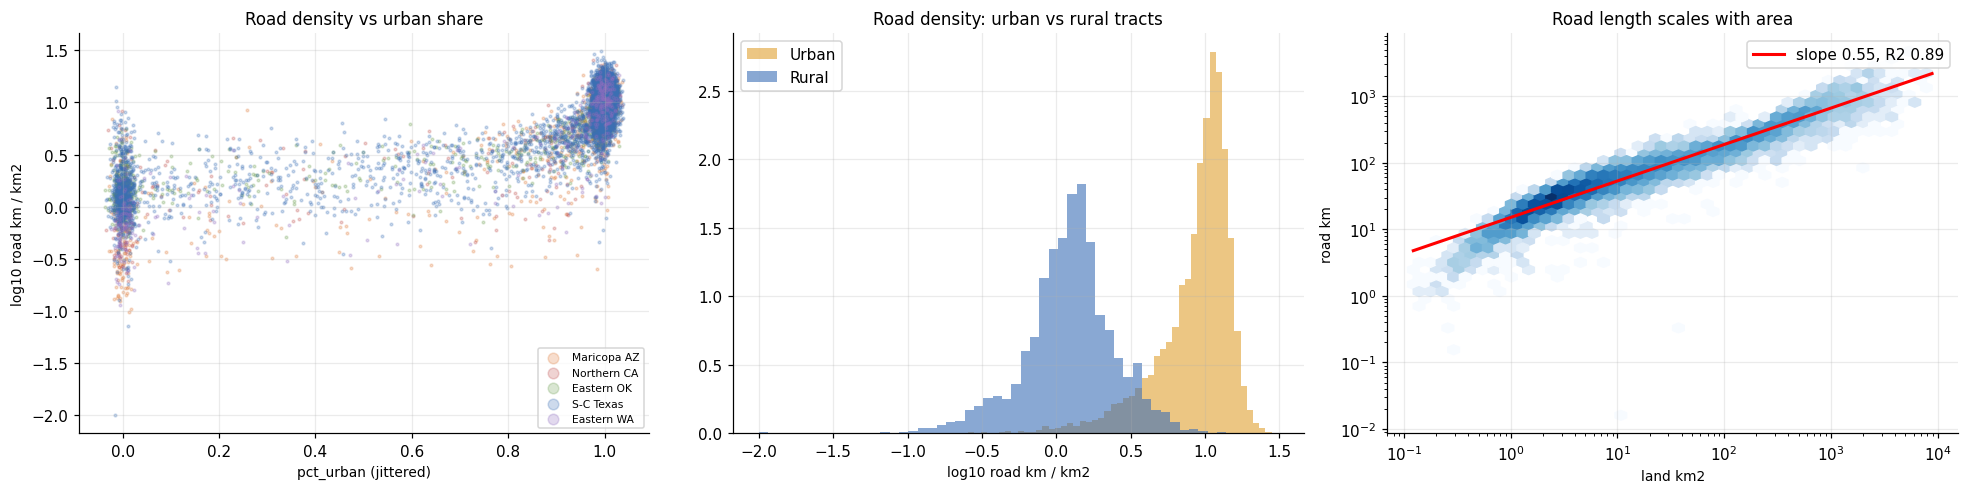

{'Rural': 1.27, 'Urban': 10.03} | log-log slope 0.55, R2 0.89
Spearman road density vs pct_urban: 0.81 | vs building density: 0.88


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.6))
for r in REG: d_ = df[df.region == r]; ax[0].scatter(d_.pct_urban + np.random.default_rng(0).normal(0, .012, len(d_)), np.log10(d_.road_km_per_km2.clip(lower=.01)), s=3, alpha=.25, color=COL[r], label=NAME[r])
ax[0].set(xlabel="pct_urban (jittered)", ylabel="log10 road km / km2", title="Road density vs urban share"); ax[0].legend(markerscale=4, fontsize=7)
for u, c in (("Urban", "#e0a030"), ("Rural", "#3b6fb6")): ax[1].hist(np.log10(df[df.ur_class == u].road_km_per_km2.clip(lower=.01)), bins=50, alpha=.6, color=c, label=u, density=True)
ax[1].legend(); ax[1].set_title("Road density: urban vs rural tracts"); ax[1].set_xlabel("log10 road km / km2")
d = df[(df.road_km_all > 0) & (df.land_km2 > 0)]; lx, ly = np.log10(d.land_km2), np.log10(d.road_km_all); sl, ic, rr, p, se = stats.linregress(lx, ly)
ax[2].hexbin(d.land_km2, d.road_km_all, gridsize=45, xscale="log", yscale="log", cmap="Blues", mincnt=1, bins="log"); xs = np.linspace(lx.min(), lx.max(), 50); ax[2].plot(10 ** xs, 10 ** (ic + sl * xs), "r", lw=2, label=f"slope {sl:.2f}, R2 {rr ** 2:.2f}"); ax[2].set(xlabel="land km2", ylabel="road km", title="Road length scales with area"); ax[2].legend()
plt.tight_layout(); plt.show(); print(df.groupby("ur_class").road_km_per_km2.median().round(2).to_dict(), f"| log-log slope {sl:.2f}, R2 {rr ** 2:.2f}"); print("Spearman road density vs pct_urban:", round(stats.spearmanr(df.road_km_per_km2, df.pct_urban, nan_policy="omit")[0], 2), "| vs building density:", round(stats.spearmanr(df.road_km_per_km2, df.bldg_per_km2, nan_policy="omit")[0], 2))

**Takeaway:** road density tracks urbanity: median 10.0 km/km2 in urban tracts vs 1.3 in rural, Spearman 0.81 with `pct_urban` and 0.88 with building density, so roads and buildings carry almost the same information about density. Road length grows with land area at a log-log slope of 0.55 (R2 0.89): doubling a tract's area adds only about 46% more road, so raw road length must never be compared across tracts of different size.

## 5. Rail and transit

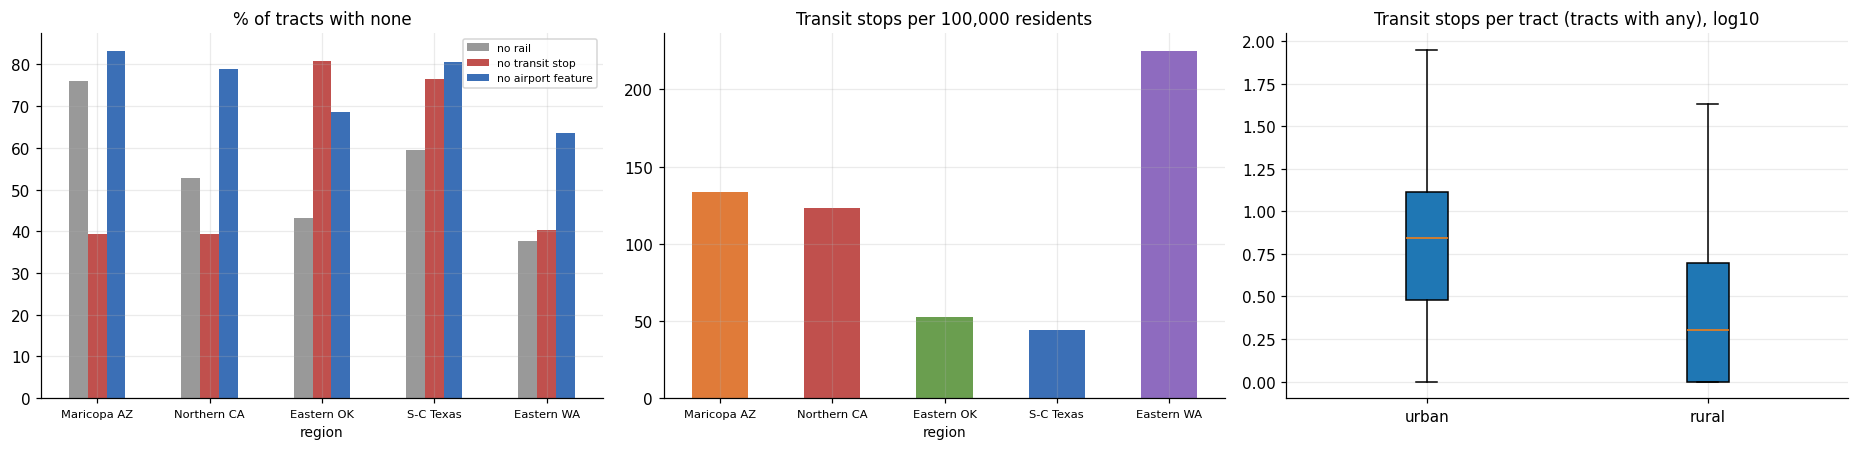

                  no rail  no transit stop  no airport feature
region                                                        
maricopa-az          76.0             39.0                83.0
northern-ca          53.0             39.0                79.0
eastern-ok           43.0             81.0                69.0
south-central-tx     60.0             76.0                81.0
eastern-wa           38.0             40.0                64.0

share of tracts with no transit stop, urban vs rural: {'Rural': 0.93, 'Urban': 0.61}


In [6]:
none = pd.DataFrame({"no rail": df.groupby("region").rail_km.apply(lambda s: (s == 0).mean()), "no transit stop": df.groupby("region").infra_n_transit.apply(lambda s: (s == 0).mean()), "no airport feature": df.groupby("region").infra_n_airport.apply(lambda s: (s == 0).mean())}).reindex(REG)
stops = df.groupby("region").infra_n_transit.sum().reindex(REG) / df.groupby("region").pop_total.sum().reindex(REG) * 1e5
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2)); (none * 100).plot.bar(ax=ax[0], rot=0, color=["#999", "#c0504d", "#3b6fb6"]); ax[0].set_xticklabels([NAME[r] for r in REG], fontsize=7.5); ax[0].set_title("% of tracts with none"); ax[0].legend(fontsize=7)
stops.plot.bar(ax=ax[1], rot=0, color=[COL[r] for r in REG]); ax[1].set_xticklabels([NAME[r] for r in REG], fontsize=7.5); ax[1].set_title("Transit stops per 100,000 residents")
ax[2].boxplot([np.log10(df.loc[(df.ur_class == u) & (df.infra_n_transit > 0), "infra_n_transit"]) for u in ("Urban", "Rural")], patch_artist=True); ax[2].set_xticklabels(["urban", "rural"]); ax[2].set_title("Transit stops per tract (tracts with any), log10")
plt.tight_layout(); plt.show(); print((none * 100).round(0).to_string()); print("\nshare of tracts with no transit stop, urban vs rural:", df.groupby("ur_class").no_transit.mean().round(2).to_dict())

**Takeaway:** rail and transit are scarce and uneven. 38% (Eastern WA) to 76% (Maricopa) of tracts have no rail, and 64-83% have no airport feature. Oklahoma and Texas have no transit stop in 81% and 76% of tracts versus 39-40% in the other regions. Transit absence is mostly rural (93% of rural tracts have no stop) but also common in cities (61% of urban tracts), so stop presence is a weak urbanity signal.

## 6. Map of road density and highway presence

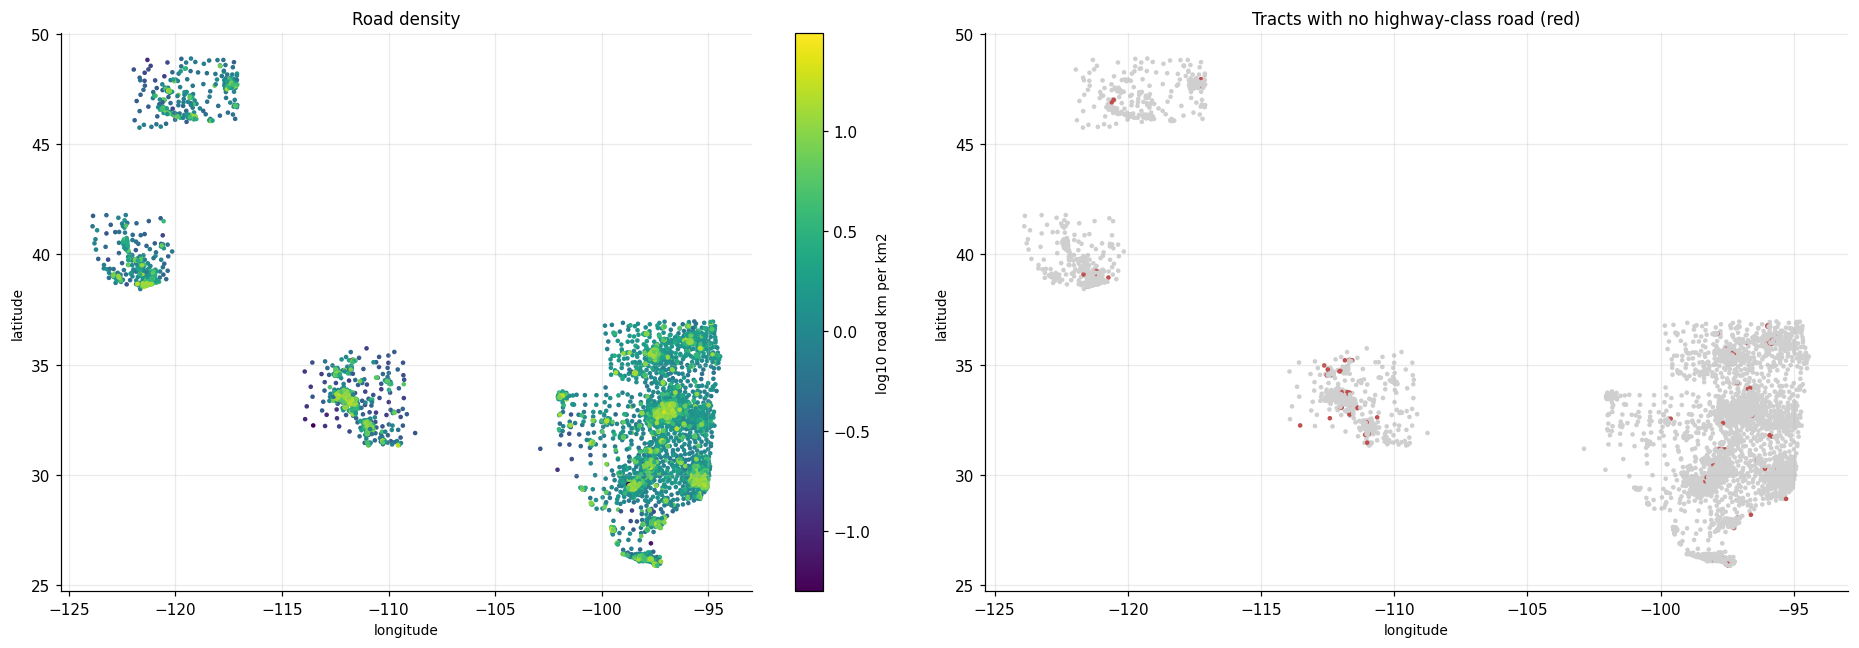

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(17, 6))
sc = ax[0].scatter(df.INTPTLON, df.INTPTLAT, c=np.log10(df.road_km_per_km2.clip(lower=.05)), s=4, cmap="viridis"); plt.colorbar(sc, ax=ax[0], label="log10 road km per km2"); ax[0].set_title("Road density")
ax[1].scatter(df.INTPTLON, df.INTPTLAT, c=np.where(df.road_km_hwy > 0, "#cfcfcf", "#c0504d"), s=4); ax[1].set_title("Tracts with no highway-class road (red)")
for a in ax: a.set(xlabel="longitude", ylabel="latitude")
plt.tight_layout(); plt.show()

**Takeaway:** road density follows the metro clusters. The tracts with no highway-class road (red, right) are not remote: they sit inside metro areas (a visible cluster in Maricopa, the rest scattered through Texas), 75% of them are urban and their median land area is 5 km2. They are ordinary suburban tracts that happen not to touch a motorway-to-secondary road, so the road component may be undefined there.